In [3]:
import pandas as pd
from pathlib import Path

RAW_DATA_PATH = Path("../Data/Raw/PhiUSIIL_Phishing_URL_Dataset.csv")

df = pd.read_csv(RAW_DATA_PATH , usecols=['URL','label'])

print("Số lượng url ban đầu: ",len(df))
df.head()

Số lượng url ban đầu:  235795


,URL,label
0,https://www.southbankmosaics.com,1
1,https://www.uni-mainz.de,1
2,https://www.voicefmradio.co.uk,1
3,https://www.sfnmjournal.com,1
4,https://www.rewildingargentina.org,1


In [4]:
print("Số giá trị rỗng: ")
print(df.isnull().sum())
#xóa bỏ các ô rỗng
df = df.dropna()

Số giá trị rỗng: 
URL      0
label    0
dtype: int64


In [5]:
#Kiểm tra giá trị trùng lặp
print("Số URL bị trùng lặp: ",df.duplicated(subset=['URL']).sum())
#Xóa các url trùng lặp
df = df.drop_duplicates(subset=['URL'])

print("Số lượng url sau khi làm sạch: ",len(df))


Số URL bị trùng lặp:  425
Số lượng url sau khi làm sạch:  235370


In [6]:
#Đếm tỷ lệ nhãn
df['label'].value_counts()

label
1    134850
0    100520
Name: count, dtype: int64

[Text(0, 3, '134,850'), Text(0, 3, '100,520')]

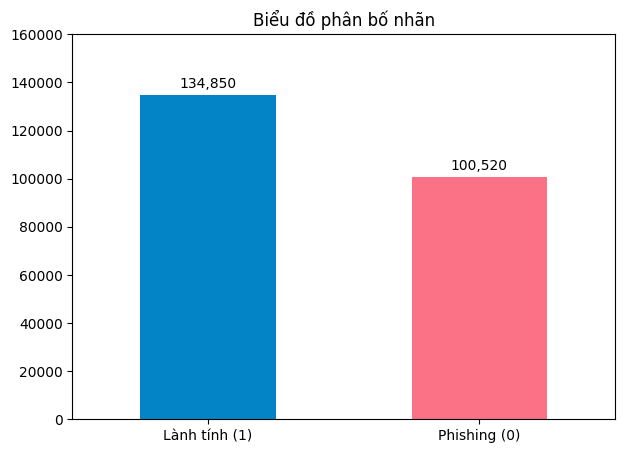

In [14]:
#Vẽ biểu đồ 
counts = df['label'].value_counts()
counts.index = ['Lành tính (1)','Phishing (0)']

ax = counts.plot(
    kind = 'bar',
    color=["#0284c7", "#fb7185"],
    rot = 0,
    title = 'Biểu đồ phân bố nhãn',
    figsize = (7,5),
)
ax.set_ylim(0, 160000)
ax.bar_label(ax.containers[0], fmt=lambda x: f"{int(x):,}", padding=3)

In [15]:
df = df.rename(columns={'URL':'url'})

OUTPUT_PATH = Path("../Data/Interim/urls_cleaned.csv")

df.to_csv(OUTPUT_PATH, index = False)
